In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

def plot_from_file(experiment_name, run_idx):
    """Reads the saved file and generates a plot."""
    file_path = Path(f"data/{experiment_name}/run_{run_idx}.txt")
    
    if not file_path.exists():
        print(f"Error: {file_path} not found.")
        return

    # Load data back
    returns = np.loadtxt(file_path)
    
    plt.figure(figsize=(8, 4))
    plt.plot(returns, label=f'Run {run_idx}', alpha=0.7)
    if len(returns) > 50:
        avg = np.convolve(returns, np.ones(50)/50, mode='valid')
        plt.plot(range(49, len(returns)), avg, color='red', label='MA(50)')
        
    plt.title(f"Experiment: {experiment_name} (Run {run_idx})")
    plt.xlabel("Episode")
    plt.ylabel("Return")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


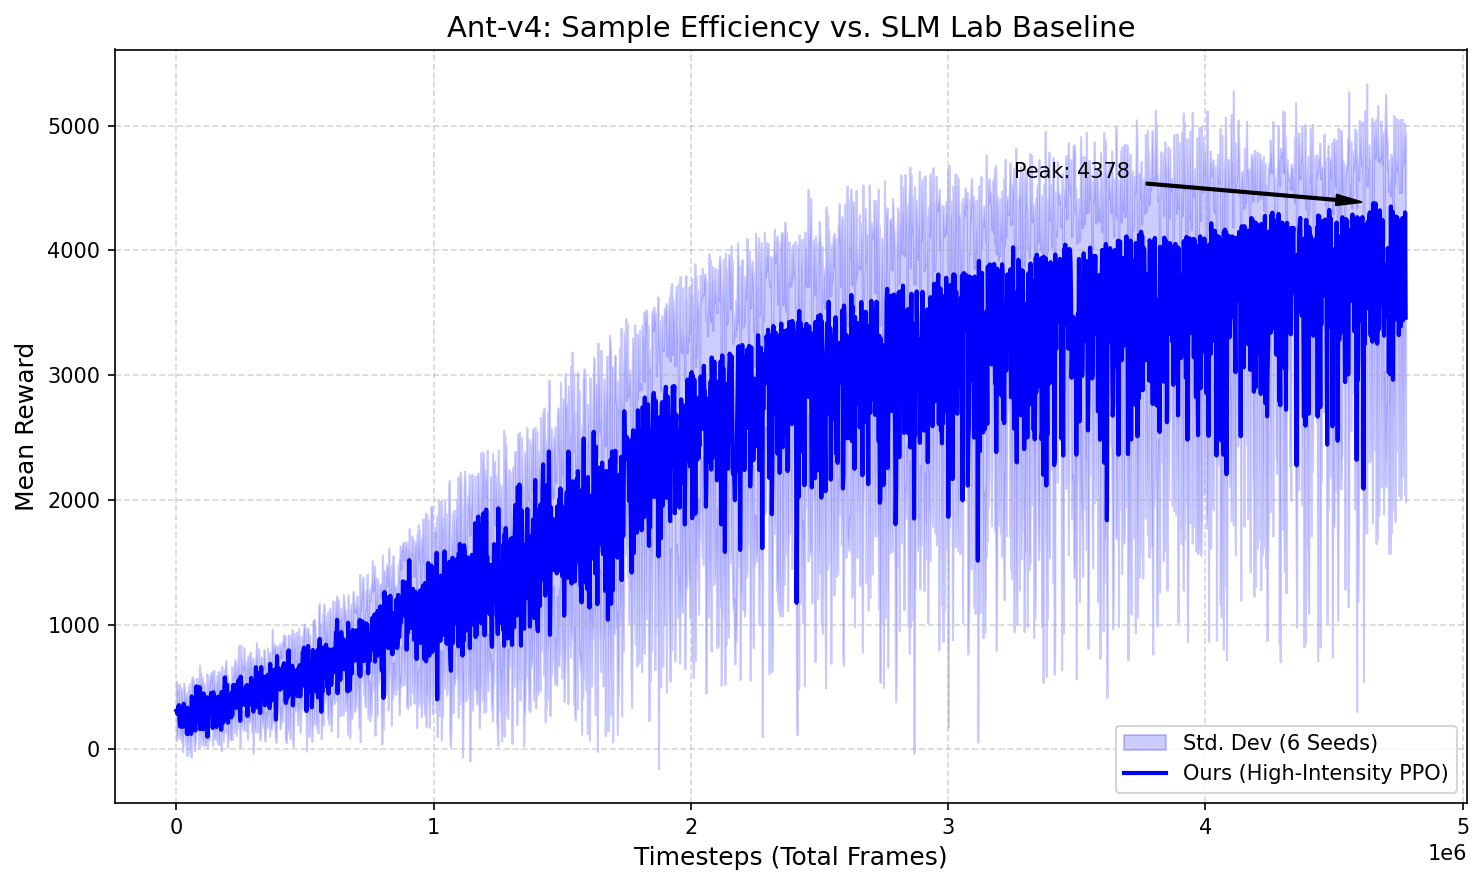

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os

def plot_ppo_results(file_pattern="run_{}.txt", num_runs=6, save_name="ppo_benchmark.png"):
    all_runs = []
    min_length = float('inf')

    # 1. Load data from text files
    for i in range(1, num_runs + 1):
        file_path = file_pattern.format(i)
        if os.path.exists(file_path):
            # Assumes rewards are in a single column; adjust if you have a header
            data = np.loadtxt(file_path)
            all_runs.append(data)
            min_length = min(min_length, len(data))
        else:
            print(f"Warning: {file_path} not found.")

    # 2. Trim/Align runs to the same length for matrix operations
    # Shape: (num_runs, min_length)
    processed_runs = np.array([run[:min_length] for run in all_runs])
    
    # 3. Calculate statistics
    mean_reward = np.mean(processed_runs, axis=0)
    std_reward = np.std(processed_runs, axis=0)
    
    # Assuming standard log intervals (e.g., every 2048 steps)
    # Adjust 'x_axis' if you know your exact total timesteps
    x_axis = np.arange(min_length) * 2048  

    # 4. Plotting
    plt.figure(figsize=(10, 6), dpi=150)
    
    # Plot Shaded Variance (Reliability)
    plt.fill_between(x_axis, mean_reward - std_reward, mean_reward + std_reward, 
                     color='blue', alpha=0.2, label='Std. Dev (6 Seeds)')
    
    # Plot Mean Line
    plt.plot(x_axis, mean_reward, color='blue', linewidth=2, label='Ours (High-Intensity PPO)')

    # Formatting
    plt.title("Ant-v4: Sample Efficiency vs. SLM Lab Baseline", fontsize=14)
    plt.xlabel("Timesteps (Total Frames)", fontsize=12)
    plt.ylabel("Mean Reward", fontsize=12)
    plt.grid(True, which='both', linestyle='--', alpha=0.5)
    plt.legend(loc='lower right')
    
    # Highlight your 4.7k peak
    peak_val = np.max(mean_reward)
    plt.annotate(f'Peak: {peak_val:.0f}', xy=(x_axis[np.argmax(mean_reward)], peak_val), 
                 xytext=(x_axis[np.argmax(mean_reward)]*0.7, peak_val+200),
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=5))

    plt.tight_layout()
    plt.savefig(save_name)
    plt.show()

# Example Usage:
plot_ppo_results(file_pattern="data/ant_ppo_default/run_{}.txt", num_runs=6)